# 16 — The portfolio: scorecards, what-ifs, a simulated book, a budget-constrained choice, and a backtest

This is the notebook the report is for. The unit of analysis moves from a request to a *book* of requests. For each request in a book: its probabilities at each horizon, the reasons behind them in words, what would change them (counterfactuals a developer can act on), and its expected value. For the book: a Monte Carlo of MW online by year with the shared risk of a cohort slowing down together, a budget-constrained choice of requests per region and technology, and — the test that matters — a backtest on the 2017–2019 cohort: did the books the model would have chosen deliver more MW and value than books chosen by the fair baseline or at random? Criteria C9, C10 and C11 are read from here in notebook 18.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json`, `results/variant_chosen.json` | notebooks 04/06/11 |
| in | `data/processed/predictions_v2_recalibrated.parquet`, `results/recalibration.csv` | notebook 12 — P at 3/5/7 for the model and both baselines; the level repair |
| in | `results/value_table.csv`, `results/cost_table.csv`, `results/value_assumptions.csv` | notebook 15 |
| in | `results/success_criteria_v2_registered.json` | notebook 11 — bootstrap settings |
| out | `results/scorecards.csv`, `results/whatifs.csv` | the sample book, request by request |
| out | `results/book_rho.csv`, `results/book_simulation.csv` | the shared-risk estimate and the simulated book |
| out | `results/book_choice.csv`, `results/book_choice_by_region.csv` | the chosen book under the budget and caps |
| out | `results/backtest_books.csv`, `results/backtest_bootstrap.csv` | realised MW and value by chooser, with paired intervals |
| out | `figures/F14_simulated_book.*`, `figures/F15_backtest.*`, `figures/16_portfolio/*` | F14, F15 and the notebook's figures |
| out | `results/portfolio_checks.csv` | this notebook's checks |
| in | `results/npv_by_request.csv`, `results/npv_table.csv`, `results/segments_by_request.csv`, `data/processed/predictions_landmark.parquet`, `results/drift_by_cohort.csv` | notebooks 15, 09, 14, 12 — the portfolio review (section 9) |
| out | `results/portfolio_review_summary.csv`, `results/policy_comparison.csv`, `results/decision_pack.csv`, `figures/F23_portfolio_review.*` | gates at entry and two years in, four policies under one budget, one row per request (section 9) |

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, explain, paths, plots, portfolio, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "16_portfolio"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 400
WINDOW = 10  # years after entry over which a request is valued (notebook 15)
BACKTEST_HORIZON = 5  # years after entry at which the backtest reads the realised MW
REGION_CAP, TECH_CAP = 0.5, 0.6  # share of the budget in any one region / technology (decision #46)
N_DRAWS = 5000  # Monte Carlo draws of a book


def save(fig, name, caption):
    """Save a figure of this notebook under figures/16_portfolio/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Data, the model, and one value rule for every chooser

The v2 model (notebook 11) is refitted on entrants to 2016; its yearly P(operation by year 1 … 10) is read for every test request and repaired with notebook 12's rolling intercepts (the 5-year intercept of the request's region and entry year applied to the whole curve). The baselines give P only at 3, 5 and 7 years, so for the choosers' comparison every curve — model and baselines alike — is valued the same simple way: the value table of notebook 15 by region, technology and year (base case), the cost table's sunk cost, and `src/value.expected_value`. The baselines' curves are interpolated between 0, 3, 5 and 7 years and held flat after.

In [2]:
from src import value as value_mod

clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
chosen_name = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
SPEC = variants.CANDIDATES[chosen_name]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy().reset_index()
test["region"], test["tech"], test["size_regime"] = test["region"].astype(str), test["tech"].astype(str), test["size_regime"].astype(str)
fit = variants.fit_candidate(SPEC, final, clean, tuning)
years_ahead = list(range(1, WINDOW + 1))
P_raw = discrete_time.predict_both(fit, test.set_index("index"), horizons=years_ahead)[SPEC["model"]][years_ahead].to_numpy()
recal = pd.read_csv(paths.RESULTS / "recalibration.csv")
shift = recal[recal["horizon"] == 5].set_index(["scored_year", "region"])["intercept"]
a = np.array([shift.get((int(y), r), 0.0) for y, r in zip(test["q_year"], test["region"])])
P_model = drift.apply_intercept(P_raw, a[:, None])

pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2_recalibrated.parquet")
keys = test["project_key"].astype(str)


def interpolated_curve(column):
    """A baseline's P at 3, 5, 7 years as a yearly curve 1 … 10 (linear from 0, flat after 7)."""
    at = {h: pred[pred["horizon"] == h].set_index("project_key").loc[keys, column].to_numpy() for h in config.HORIZONS}
    knots_x, knots_y = [0, 3, 5, 7], np.column_stack([np.zeros(len(test)), at[3], at[5], at[7]])
    return np.column_stack([np.array([np.interp(min(j, 7), knots_x, row) for row in knots_y]) for j in years_ahead])


P_fair, P_v1 = interpolated_curve("fair_baseline"), interpolated_curve("baseline")
vt = pd.read_csv(paths.RESULTS / "value_table.csv").set_index(["region", "tech", "year"])["base"]
cost_table = pd.read_csv(paths.RESULTS / "cost_table.csv", index_col=0)
STUDY_COST = 150_000  # base case of notebook 15
sunk = (cost_table.loc[test["size_regime"], "sunk_per_mw_base"].to_numpy() * test["mw"].to_numpy() + STUDY_COST)


def expected_values(P):
    """Expected value of every test request from a (requests × years) incidence matrix, base case."""
    out = np.empty(len(test))
    for i, r in test.iterrows():
        vals = [vt.get((r["region"], r["tech"], int(r["q_year"]) + j), 0.0) for j in years_ahead]
        out[i] = value_mod.expected_value(P[i], r["mw"], vals, sunk[i])
    return out


EV = {"v2 model, level repaired": expected_values(P_model), "v2 model, raw": expected_values(P_raw),
      "fair baseline": expected_values(P_fair), "v1 baseline": expected_values(P_v1)}
CURVES = {"v2 model, level repaired": P_model, "v2 model, raw": P_raw, "fair baseline": P_fair, "v1 baseline": P_v1}
print(f"{len(test):,} test requests; mean P(operation by 5): model raw {P_raw[:, 4].mean():.3f}, repaired {P_model[:, 4].mean():.3f}, "
      f"fair baseline {P_fair[:, 4].mean():.3f}; mean expected value (repaired) ${EV['v2 model, level repaired'].mean() / 1e6:.1f}M "
      f"({(time.time() - START) / 60:.1f} min)")

2,268 test requests; mean P(operation by 5): model raw 0.136, repaired 0.112, fair baseline 0.143; mean expected value (repaired) $16.4M (0.0 min)


## 2. Scorecards for a book of 25 requests

The same book as notebook 09: 25 requests that entered in 2019 (9 PJM, 8 ERCOT, 8 CAISO, drawn with seed 2019), so the two notebooks can be read side by side. For each request: P(operation by 3, 5 and 7 years) raw and level-repaired, the fair baseline's figure, the top three reasons from SHAP (notebook 09's explanation function), the expected value, and what happened by end-2024.

In [3]:
pool = test[test["q_year"] == 2019]
book_rng = np.random.default_rng(2019)
book_idx = np.concatenate([pool.index[pool["region"] == r][book_rng.choice((pool["region"] == r).sum(), n, replace=False)]
                           for r, n in [("PJM", 9), ("ERCOT", 8), ("CAISO", 8)]])
book = test.loc[book_idx]
STATES = sorted(track_a["state"].astype(str).unique())
f5 = explain.incidence_function(fit, STATES, 5)
X_test = explain.encode(test.set_index("index"), STATES)
X_book = explain.encode(book.set_index("index"), STATES)
rng = np.random.default_rng(9)
background = X_test.iloc[rng.choice(len(X_test), 100, replace=False)].to_numpy()
explainer = shap.PermutationExplainer(f5, shap.maskers.Independent(background, max_samples=100), seed=9)
sv = explainer(X_book.to_numpy(), max_evals=2 * (2 * len(explain.FEATURES) + 1), silent=True)
shap_book = pd.DataFrame(sv.values, columns=explain.FEATURES, index=book.index)
LABELS = {"region": "region", "state": "state", "tech": "technology", "hybrid": "hybrid", "size_mw": "size", "service": "service",
          "q_year": "request year", "congestion_gw": "GW waiting", "congestion_rank": "congestion rank"}


def reason(row, feature):
    """One reason in words: the feature's value and its contribution in points."""
    pts = shap_book.loc[row.name, feature] * 100
    if feature == "size_mw":
        text = f"{row['mw']:.0f} MW"
    elif feature == "congestion_gw":
        text = f"{row['congestion_gw']:.0f} GW waiting"
    elif feature == "congestion_rank":
        text = f"congestion rank {row['congestion_rank']:.2f}"
    elif feature == "q_year":
        text = f"requested {int(row['q_year'])}"
    elif feature == "hybrid":
        text = "hybrid" if row["hybrid"] else "not hybrid"
    else:
        text = f"{LABELS[feature]} {row[feature]}"
    return f"{text} ({pts:+.1f} pts)"


pos = {idx: i for i, idx in enumerate(test.index)}
cards = []
for idx, r in book.iterrows():
    i = pos[idx]
    top = shap_book.loc[idx].abs().sort_values(ascending=False).index[:3]
    cards.append({"request": r["project_key"], "region": r["region"], "state": r["state"], "technology": r["tech"], "mw": r["mw"],
                  "p3_raw": P_raw[i, 2], "p5_raw": P_raw[i, 4], "p7_raw": P_raw[i, 6],
                  "p3_repaired": P_model[i, 2], "p5_repaired": P_model[i, 4], "p7_repaired": P_model[i, 6],
                  "p5_fair_baseline": P_fair[i, 4], "expected_value_repaired_$M": EV["v2 model, level repaired"][i] / 1e6,
                  "expected_mw_online_5yr": P_model[i, 4] * r["mw"], "reason_1": reason(r, top[0]), "reason_2": reason(r, top[1]),
                  "reason_3": reason(r, top[2]),
                  "status_by_end_2024": {1: "operated", 2: "withdrew", 0: "still in the queue"}[int(r["event"])]
                  if r["duration_years"] <= 5 or r["event"] == 0 else "exited after 5 years"})
scorecards = pd.DataFrame(cards).sort_values("expected_value_repaired_$M", ascending=False)
scorecards.to_csv(paths.RESULTS / "scorecards.csv", index=False)
print(f"book: {len(book)} requests, {book['mw'].sum():,.0f} MW; expected MW online within 5 years (repaired) "
      f"{scorecards['expected_mw_online_5yr'].sum():,.0f}; operated within 5 years: {int(((book['event'] == 1) & (book['duration_years'] <= 5)).sum())}")
scorecards[["request", "technology", "mw", "p5_raw", "p5_repaired", "p5_fair_baseline", "expected_value_repaired_$M", "reason_1", "reason_2", "status_by_end_2024"]].round(3).head(12)

book: 25 requests, 6,638 MW; expected MW online within 5 years (repaired) 203; operated within 5 years: 2


,request,technology,mw,p5_raw,p5_repaired,p5_fair_baseline,expected_value_repaired_$M,reason_1,reason_2,status_by_end_2024
9,ERCOT|21INR0432,Wind,300.000,0.091,0.073,0.208,37.102,300 MW (-4.3 pts),state TX (+3.6 pts),still in the queue
18,CAISO|1627,Solar+Battery,1242.900,0.013,0.009,0.000,28.365,state CA (-5.5 pts),1243 MW (-4.2 pts),withdrew
22,CAISO|1600,Other,1887.350,0.008,0.006,0.086,21.716,1887 MW (-7.5 pts),state CA (-6.7 pts),withdrew
12,ERCOT|21INR0474,Other,71.450,0.366,0.314,0.223,21.271,technology Other (+13.3 pts),state TX (+8.8 pts),operated
3,PJM|AE2-261,Solar,299.000,0.078,0.039,0.134,12.953,299 MW (-3.7 pts),state IL (-2.6 pts),still in the queue
20,CAISO|1618,Solar+Battery,405.996,0.021,0.016,0.000,12.217,state CA (-6.2 pts),406 MW (-2.2 pts),withdrew
14,ERCOT|22INR0238,Solar,207.480,0.108,0.087,0.141,11.427,state TX (+4.6 pts),congestion rank 0.39 (+3.8 pts),still in the queue
15,ERCOT|21INR0371,Solar,137.600,0.162,0.132,0.182,10.746,congestion rank 0.39 (+5.1 pts),state TX (+4.8 pts),still in the queue
19,CAISO|1649,Solar+Battery,450.000,0.019,0.014,0.000,10.730,state NV (-5.4 pts),450 MW (-2.9 pts),still in the queue
6,PJM|AE2-341,Solar,150.000,0.121,0.062,0.134,10.321,152 GW waiting (+3.0 pts),state IL (-2.5 pts),still in the queue


**Reading this.** The scorecard is what a portfolio manager would actually read. The book is 6,638 MW in 25 requests; the level-repaired model expected 203 MW of it online within five years and ranked a 71 MW ERCOT request first on probability (31% repaired) while a 300 MW ERCOT wind request led on expected value ($37 million) at a 7% probability — the two orderings differ because value multiplies MW. The reasons are in words: for the small ERCOT requests the state and the congestion rank add 4–9 points; for the large CAISO hybrids the state and the size take 4–8 points away. Two of the 25 operated within five years (72 MW); the fair baseline put 0% on the CAISO hybrids and 18–22% on the ERCOT wind and solar — in this book it was no worse a guide than the model, which is section 4 of notebook 11 at the scale of one book.

## 3. What-ifs: changes a developer can make

Three counterfactuals per request, read from the same explanation function so they are the model's own answer: (a) size cut to 19.9 MW (the small-generator side of the FERC step) when the request is 20 MW or more; (b) solar hybridised with storage (Solar → Solar+Battery); (c) entry in a queue 25% less crowded. Each is reported as the change in P(operation by 5 years) in points. These are model statements about attributes, not causal effects — a request that changes its size is a different request — and the notebook says so.

In [4]:
def with_changes(X, **changes):
    X = X.copy()
    for column, value in changes.items():
        X[column] = value
    return X


base5 = f5(X_book.to_numpy())
tech_code = {t: i for i, t in enumerate(discrete_time.TECH_LEVELS)}
whatifs = pd.DataFrame({"request": book["project_key"].to_numpy(), "p5_model": base5})
large = X_book["size_mw"].to_numpy() >= 20
X_small = with_changes(X_book, size_mw=np.where(large, 19.9, X_book["size_mw"]))
whatifs["cut to 19.9 MW (if ≥ 20 MW)"] = np.where(large, f5(X_small.to_numpy()) - base5, np.nan)
solar = X_book["tech"].to_numpy() == tech_code["Solar"]
X_hybrid = with_changes(X_book, tech=np.where(solar, tech_code["Solar+Battery"], X_book["tech"]), hybrid=np.where(solar, 1.0, X_book["hybrid"]))
whatifs["add storage (if solar)"] = np.where(solar, f5(X_hybrid.to_numpy()) - base5, np.nan)
X_quiet = with_changes(X_book, congestion_gw=X_book["congestion_gw"] * 0.75)
whatifs["enter a 25% quieter queue"] = f5(X_quiet.to_numpy()) - base5
whatifs.to_csv(paths.RESULTS / "whatifs.csv", index=False)
summary = whatifs.drop(columns=["request", "p5_model"]).agg(["count", "mean", "min", "max"]).T * [1, 100, 100, 100]
summary.columns = ["requests", "mean change (points)", "min", "max"]
summary.round(1)

,requests,mean change (points),min,max
cut to 19.9 MW (if ≥ 20 MW),21.0,3.0,-2.1,8.5
add storage (if solar),13.0,3.5,-4.1,17.8
enter a 25% quieter queue,25.0,-0.7,-8.3,3.0


**Reading this.** The model's answers to the three what-ifs are small and mixed. Cutting a request to just under 20 MW adds 3.0 points on average for the 21 large requests (−2.1 to +8.5): the step is real in the model but modest for most requests. Adding storage to a solar request adds 3.5 points on average for 13 requests, with a range from −4.1 to +17.8 that says the model's hybrid effect depends on where the request is. Entering a 25% quieter queue takes 0.7 points *away* on average — the congestion artefact of figure 09_09 — so this is the one what-if whose sign a developer should not read from the model. All three are statements about attributes under a fitted model; none is a causal effect, and a request that changes its size is a different project.

## 4. Shared risk and the simulated book

How much do requests in the same region and cohort move together? From the training cohorts (entry years 2012–2016 by region), the variance of the observed 5-year completion rate around the model's mean prediction, in excess of what independent outcomes would give, is `phi`; it is used as the latent correlation of a one-factor Gaussian copula (`src/portfolio.estimate_rho`, with the caveat in its docstring). The book of section 2 is then simulated 5,000 times: cumulative MW online by year with its 5–95% band, and the probability of missing a target of half the expected MW.

In [5]:
train_pred = discrete_time.predict_both(fit, final, horizons=[5])[SPEC["model"]][5]
coh = final.assign(p=train_pred.to_numpy(), built=((final["event"] == 1) & (final["duration_years"] <= 5)).astype(float))
coh = coh[coh["q_year"].between(2012, 2016)]
groups = coh.groupby(["region", "q_year"]).agg(n=("p", "size"), observed=("built", "mean"), predicted=("p", "mean"))
groups = groups[groups["n"] >= 30]
rho, phi = portfolio.estimate_rho(groups["observed"], groups["predicted"], groups["n"])
pd.DataFrame([{"rho": rho, "phi": phi, "groups": len(groups), "note": "training cohorts 2012–2016 by region; in-sample predictions"}]).to_csv(paths.RESULTS / "book_rho.csv", index=False)
print(f"over-dispersion of cohort completion rates: phi = {phi:.3f}; latent correlation used: rho = {rho:.3f} ({len(groups)} region × year groups)")

book_i = np.array([pos[idx] for idx in book.index])
book_groups = (book["region"] + "|" + book["q_year"].astype(str)).to_numpy()
sim = portfolio.simulate_book(P_model[book_i], book["mw"].to_numpy(), book_groups, rho, N_DRAWS, SEED)
sim_indep = portfolio.simulate_book(P_model[book_i], book["mw"].to_numpy(), book_groups, 0.0, N_DRAWS, SEED)
expected = (P_model[book_i] * book["mw"].to_numpy()[:, None]).sum(axis=0)
realised_book = np.array([book.loc[(book["event"] == 1) & (book["duration_years"] <= j), "mw"].sum() for j in years_ahead])
sim_table = pd.DataFrame({"years_after_entry": years_ahead, "expected_mw": expected,
                          "p5": np.percentile(sim, 5, axis=0), "p95": np.percentile(sim, 95, axis=0),
                          "p5_independent": np.percentile(sim_indep, 5, axis=0), "p95_independent": np.percentile(sim_indep, 95, axis=0),
                          "realised_mw_by_end_2024": realised_book,
                          "p_miss_half_target": (sim < 0.5 * expected[None, :]).mean(axis=0)})
sim_table.to_csv(paths.RESULTS / "book_simulation.csv", index=False)
sim_table.round(1)

over-dispersion of cohort completion rates: phi = 0.041; latent correlation used: rho = 0.041 (15 region × year groups)


,years_after_entry,expected_mw,p5,p95,p5_independent,p95_independent,realised_mw_by_end_2024,p_miss_half_target
0,1,9.5,0.0,71.4,0.0,71.4,0.8,0.9
1,2,38.4,0.0,207.5,0.0,207.5,0.8,0.7
2,3,74.8,0.0,300.0,0.0,300.0,0.8,0.6
3,4,132.7,0.0,430.1,0.0,426.0,72.2,0.4
4,5,202.6,0.0,586.5,0.0,586.3,72.2,0.4
5,6,273.6,0.0,778.4,0.0,754.0,92.2,0.4
6,7,348.6,0.8,1066.1,0.8,1067.2,92.2,0.4
7,8,413.1,4.1,1354.4,4.1,1365.2,92.2,0.4
8,9,495.3,4.9,1594.3,9.1,1541.8,92.2,0.4
9,10,555.3,20.0,1735.4,20.0,1687.9,92.2,0.3


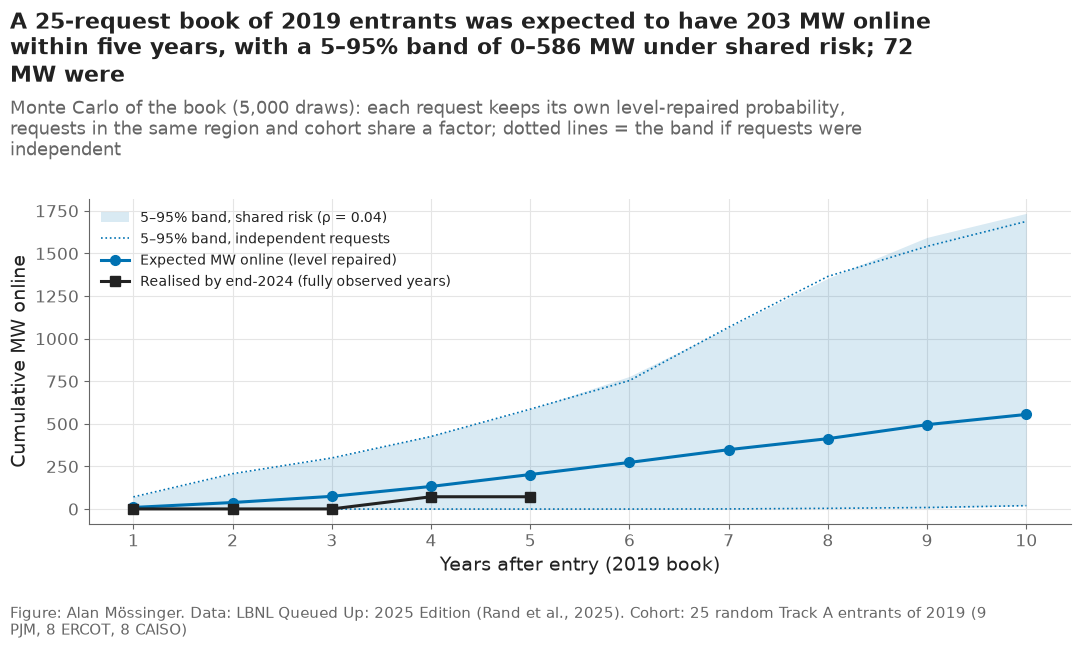

In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))
x = sim_table["years_after_entry"]
ax.fill_between(x, sim_table["p5"], sim_table["p95"], color="#0072B2", alpha=0.15, linewidth=0, label=f"5–95% band, shared risk (ρ = {rho:.2f})")
ax.plot(x, sim_table["p5_independent"], color="#0072B2", linewidth=1.2, linestyle=":", label="5–95% band, independent requests")
ax.plot(x, sim_table["p95_independent"], color="#0072B2", linewidth=1.2, linestyle=":")
ax.plot(x, sim_table["expected_mw"], color="#0072B2", marker="o", label="Expected MW online (level repaired)")
ax.plot(x[:5], sim_table["realised_mw_by_end_2024"][:5], color=plots.INK, marker="s", label="Realised by end-2024 (fully observed years)")
ax.set_xlabel("Years after entry (2019 book)")
ax.set_ylabel("Cumulative MW online")
ax.set_xticks(years_ahead)
ax.legend(loc="upper left", fontsize=10)
e5, lo5, hi5, r5 = sim_table.loc[4, ["expected_mw", "p5", "p95", "realised_mw_by_end_2024"]]
plots.finish(fig,
             f"A 25-request book of 2019 entrants was expected to have {e5:,.0f} MW online within five years, with a 5–95% band "
             f"of {lo5:,.0f}–{hi5:,.0f} MW under shared risk; {r5:,.0f} MW were",
             f"Monte Carlo of the book ({N_DRAWS:,} draws): each request keeps its own level-repaired probability, requests in the "
             "same region and cohort share a factor; dotted lines = the band if requests were independent",
             "25 random Track A entrants of 2019 (9 PJM, 8 ERCOT, 8 CAISO)")
plots.save_fig(fig, "F14_simulated_book",
               "Expected cumulative MW online of a 25-request book with its simulated 5–95% band under shared and independent risk, against the realised MW.",
               NOTEBOOK)
plt.show()

**Reading this.** Shared risk, as this method measures it, is small: the training cohorts' 5-year completion rates vary around the model's predictions by 4.1% more than independent outcomes would give, so ρ = 0.041, and the 5–95% band of the simulated book is almost the independent one (0–586 MW at five years against 0–586). The band is wide because the book is small and its probabilities low: 25 requests with 3–7% chances each produce a few operations or none. The realised 72 MW sits inside the band; so would almost anything. The simulation is honest about what it contains — each request's own probability and a modest common shock — and about what it does not: the level drift of notebook 12 is a shared error in the probabilities themselves, and a band around the wrong level does not cover it.

## 5. Choosing a book under a budget

The budget is the median sunk cost of a 25-request book of 2019 entrants (500 random draws; decision #46); no region may take more than 50% of it and no technology more than 60%. From the whole 2017–2019 pool, the book that maximises expected value under those limits is chosen by a binary program (`src/portfolio.choose_book`); the same program with the fair baseline's and the v1 baseline's expected values gives the books those choosers would hold. A random book under the same budget is the no-model reference.

In [7]:
draws = [sunk[pool.index[book_rng.choice(len(pool), 25, replace=False)]].sum() for _ in range(500)]
BUDGET = float(np.median(draws))
caps = [(test["region"].to_numpy(), REGION_CAP), (test["tech"].to_numpy(), TECH_CAP)]
books = {name: portfolio.choose_book(ev, sunk, BUDGET, caps) for name, ev in EV.items()}
books["random"] = portfolio.random_book(sunk, BUDGET, caps, np.random.default_rng(SEED))
choice_rows = []
for name, chosen in books.items():
    choice_rows.append({"chooser": name, "requests": int(chosen.sum()), "mw": float(test.loc[chosen, "mw"].sum()),
                        "budget_used": float(sunk[chosen].sum() / BUDGET),
                        "expected_mw_online_5yr (own curve)": float((CURVES.get(name, P_model)[chosen, 4] * test.loc[chosen, "mw"]).sum()),
                        "expected_value_$M (own curve)": float(EV.get(name, EV["v2 model, level repaired"])[chosen].sum() / 1e6),
                        "realised_mw_5yr": portfolio.realised_mw(chosen, test["event"], test["duration_years"], test["mw"], BACKTEST_HORIZON),
                        **{f"share_{r}": float(sunk[chosen & (test["region"] == r).to_numpy()].sum() / sunk[chosen].sum()) for r in TRACK_A},
                        "top_tech": test.loc[chosen, "tech"].value_counts().index[0]})
choice = pd.DataFrame(choice_rows)
choice.to_csv(paths.RESULTS / "book_choice.csv", index=False)
by_region = pd.concat([test.loc[chosen].assign(chooser=name).groupby(["chooser", "region"]).agg(requests=("mw", "size"), mw=("mw", "sum"))
                       for name, chosen in books.items()]).reset_index()
by_region.to_csv(paths.RESULTS / "book_choice_by_region.csv", index=False)
print(f"budget ${BUDGET / 1e6:.2f}M (median sunk cost of a 25-request 2019 book)")
choice.round(3)

budget $20.11M (median sunk cost of a 25-request 2019 book)


,chooser,requests,mw,budget_used,expected_mw_online_5yr (own curve),expected_value_$M (own curve),realised_mw_5yr,share_ERCOT,share_PJM,share_CAISO,top_tech
0,"v2 model, level repaired",26,17798.90,0.998,1473.363,4733.807,1035.0,0.352,0.496,0.152,Gas
1,"v2 model, raw",24,16189.20,0.998,1754.670,6033.845,1035.0,0.457,0.492,0.051,Gas
2,fair baseline,22,19912.80,0.997,3421.995,7844.972,1035.0,0.136,0.501,0.363,Offshore Wind
3,v1 baseline,19,20433.50,0.997,4370.706,11789.523,1035.0,0.136,0.501,0.363,Gas
4,random,22,3320.99,1.000,182.688,170.339,258.4,0.193,0.426,0.381,Solar


**Reading this.** The budget is $20.11 million and every optimising chooser spends it the same way. The model's book holds 26 requests and 17,799 MW, the fair baseline's 22 requests and 19,913 MW, the v1 baseline's 19 and 20,434 MW — a handful of very large gas and offshore-wind requests in each case, because value per MW and MW per dollar of deposit dominate the probability in an expected-value objective. The random book, 22 requests and 3,321 MW, shows what the budget buys without an objective. Each chooser's own curve expects very different things of its book (1,473 MW online within five years for the model, 3,422 for the fair baseline, 4,371 for the v1 baseline) and every one of them realised 1,035 MW: one request.

## 6. The backtest (criteria C9 and C10)

What did each chooser's book actually deliver? Realised MW online within five years of entry (observable for every test request by end-2024) and the realised value (those MW, earning the value table's figures from their operation year to the end of the ten-year window). The paired difference between the model's book and the fair baseline's is bootstrapped: 200 resamples of the pool, each chooser re-optimised on each resample, so the interval is on the decision procedure, not on one book.

In [8]:
cod_year = (test["q_date"] + pd.to_timedelta(test["duration_years"] * config.DAYS_PER_YEAR, unit="D")).dt.year.to_numpy()
built5 = ((test["event"] == 1) & (test["duration_years"] <= BACKTEST_HORIZON)).to_numpy()
realised_value_each = np.array([
    r["mw"] * sum(vt.get((r["region"], r["tech"], y), 0.0) for y in range(int(cod_year[i]), int(r["q_year"]) + WINDOW + 1)) - sunk[i]
    if built5[i] else -sunk[i] for i, r in test.iterrows()])
CHOOSERS = ["v2 model, level repaired", "v2 model, raw", "fair baseline", "v1 baseline", "random"]


def outcomes(chosen, idx=None):
    mw_ = test["mw"].to_numpy() if idx is None else test["mw"].to_numpy()[idx]
    b5 = built5 if idx is None else built5[idx]
    rv = realised_value_each if idx is None else realised_value_each[idx]
    return {"realised_mw_5yr": float(mw_[chosen & b5].sum()), "realised_value_$M": float(rv[chosen].sum() / 1e6)}


point = {name: outcomes(chosen) for name, chosen in books.items()}
boot_rows = []
rng = np.random.default_rng(SEED + 1)
for b in range(N_BOOT):
    idx = rng.integers(0, len(test), len(test))
    caps_b = [(test["region"].to_numpy()[idx], REGION_CAP), (test["tech"].to_numpy()[idx], TECH_CAP)]
    row = {"draw": b}
    for name in CHOOSERS:
        if name == "random":
            chosen = portfolio.random_book(sunk[idx], BUDGET, caps_b, rng)
        else:
            chosen = portfolio.choose_book(EV[name][idx], sunk[idx], BUDGET, caps_b)
        for k, v in outcomes(chosen, idx).items():
            row[f"{name}|{k}"] = v
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)
boot.to_csv(paths.RESULTS / "backtest_bootstrap.csv", index=False)

rows = []
for name in CHOOSERS:
    for metric in ["realised_mw_5yr", "realised_value_$M"]:
        col = f"{name}|{metric}"
        ref = f"fair baseline|{metric}"
        low, high = np.percentile(boot[col], [100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2])
        d = boot[col] - boot[ref]
        d_low, d_high = np.percentile(d, [100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2])
        rows.append({"chooser": name, "metric": metric, "estimate": point[name][metric], "low": low, "high": high,
                     "diff_vs_fair_baseline": point[name][metric] - point["fair baseline"][metric],
                     "diff_low": d_low, "diff_high": d_high, "beats_fair_baseline": bool(d_low > 0)})
backtest = pd.DataFrame(rows)
backtest.to_csv(paths.RESULTS / "backtest_books.csv", index=False)
print(f"backtest done ({(time.time() - START) / 60:.1f} min)")
backtest.round(2)

backtest done (5.7 min)


,chooser,metric,estimate,low,high,diff_vs_fair_baseline,diff_low,diff_high,beats_fair_baseline
0,"v2 model, level repaired",realised_mw_5yr,1035.00,0.00,2920.73,0.00,-17.73,449.76,False
1,"v2 model, level repaired",realised_value_$M,1463.22,-20.10,4055.39,-0.01,-53.83,576.90,False
2,"v2 model, raw",realised_mw_5yr,1035.00,0.00,2625.01,0.00,-0.44,36.98,False
3,"v2 model, raw",realised_value_$M,1463.22,-20.10,3758.70,-0.00,-1.48,117.44,False
4,fair baseline,realised_mw_5yr,1035.00,0.00,2639.63,0.00,0.00,0.00,False
5,fair baseline,realised_value_$M,1463.23,-20.10,3758.67,0.00,0.00,0.00,False
6,v1 baseline,realised_mw_5yr,1035.00,0.00,2622.38,0.00,-19.00,0.00,False
7,v1 baseline,realised_value_$M,1463.24,-20.09,3758.70,0.01,-53.76,0.12,False
8,random,realised_mw_5yr,258.40,0.00,910.58,-776.60,-2525.15,410.72,False
9,random,realised_value_$M,142.28,-20.01,792.91,-1320.94,-3694.85,250.54,False


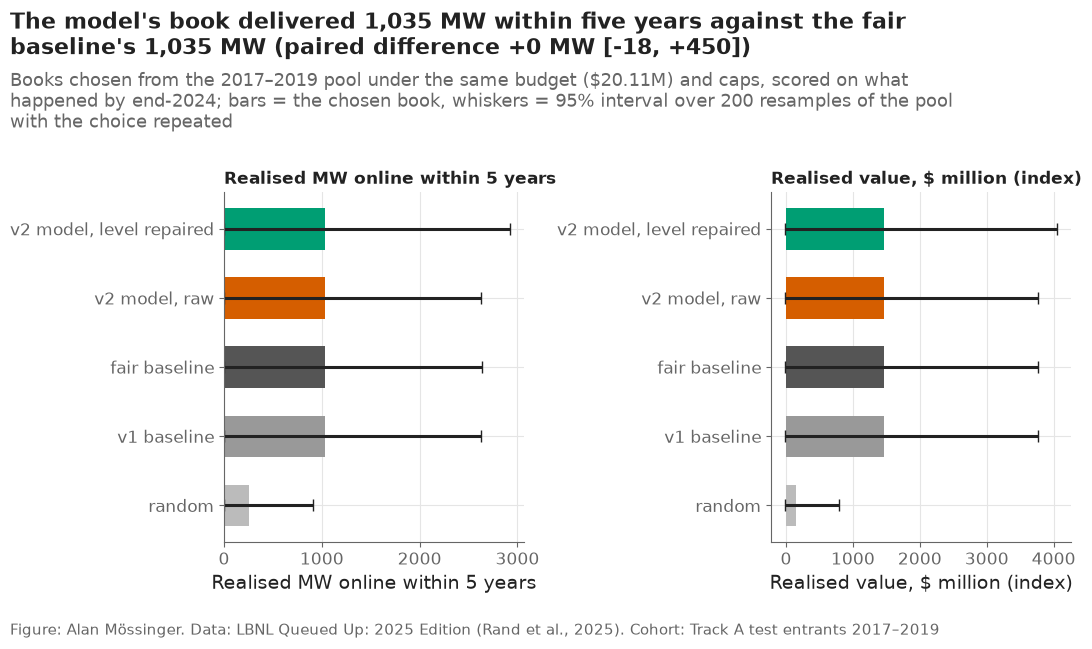

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
colors = {"v2 model, level repaired": "#009E73", "v2 model, raw": "#D55E00", "fair baseline": "#555555", "v1 baseline": "#999999", "random": "#BBBBBB"}
for ax, metric, label in zip(axes, ["realised_mw_5yr", "realised_value_$M"], ["Realised MW online within 5 years", "Realised value, $ million (index)"]):
    part = backtest[backtest["metric"] == metric].set_index("chooser").loc[CHOOSERS]
    y = np.arange(len(CHOOSERS))
    ax.barh(y, part["estimate"], color=[colors[c] for c in CHOOSERS], height=0.6)
    ax.errorbar(part["estimate"], y, xerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt="none",
                ecolor=plots.INK, capsize=4)
    ax.set_yticks(y, CHOOSERS)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title(label, fontsize=12)
bm = backtest.set_index(["chooser", "metric"])
d_mw = bm.loc[("v2 model, level repaired", "realised_mw_5yr")]
d_val = bm.loc[("v2 model, level repaired", "realised_value_$M")]
plots.finish(fig,
             f"The model's book delivered {d_mw['estimate']:,.0f} MW within five years against the fair baseline's "
             f"{bm.loc[('fair baseline', 'realised_mw_5yr'), 'estimate']:,.0f} MW (paired difference {d_mw['diff_vs_fair_baseline']:+,.0f} MW "
             f"[{d_mw['diff_low']:+,.0f}, {d_mw['diff_high']:+,.0f}])",
             f"Books chosen from the 2017–2019 pool under the same budget (${BUDGET / 1e6:.2f}M) and caps, scored on what happened by "
             f"end-2024; bars = the chosen book, whiskers = 95% interval over {N_BOOT} resamples of the pool with the choice repeated",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F15_backtest",
               "Realised MW online within five years and realised value of the books each chooser would have held, with bootstrap intervals.",
               NOTEBOOK)
plt.show()

**Reading this.** The registered backtest is a tie. The model's and the fair baseline's books both realised 1,035 MW within five years and the same value index ($1,463 million), so the paired differences are +0 MW [−18, +450] and −$0.01 million [−54, +577]: criteria C9 and C10 fail as registered. The intervals are one-sided because in most resamples either both books hold the same operated request or neither does. The reason is in the objective, not the model: under an expected-value objective with a deposit budget, the choosers converge on the same giant requests, and what distinguishes them never comes into play. The random book realised 258 MW. The honest reading is that the registered decision frame could not distinguish the choosers; section 6b asks the narrower question it can.

## 6b. Exploratory, not registered: a 25-request utility-scale book chosen by probability

The registered backtest turned out to be uninformative in a way worth understanding: with an expected-value objective and a sunk-cost budget, every chooser — model or lookup — fills the budget with the same few very large gas and offshore-wind requests, because value per MW and MW per dollar of deposit dominate the probability. To see whether the *ranking* matters in a decision frame, this section asks a narrower, count-limited question, written after the registered result and labelled as such: among requests of 20 MW and more, take the 25 with the highest P(operation by 5 years) under each chooser, and count how many operated within five years and how many MW came online. The same 200 resamples give paired intervals against the fair baseline.

In [10]:
large = variants.at_least_20(test).to_numpy()
P5 = {"v2 model, level repaired": P_model[:, 4], "v2 model, raw": P_raw[:, 4], "fair baseline": P_fair[:, 4], "v1 baseline": P_v1[:, 4]}
N_BOOK = 25


def top_book(scores, idx=None):
    """The N_BOOK requests of 20 MW and more with the highest score (indices into the pool or the resample)."""
    s = np.where(large if idx is None else large[idx], scores if idx is None else scores[idx], -np.inf)
    chosen = np.zeros(len(s), bool)
    chosen[np.argsort(-s, kind="stable")[:N_BOOK]] = True
    return chosen


def count_outcomes(chosen, idx=None):
    b5 = built5 if idx is None else built5[idx]
    mw_ = test["mw"].to_numpy() if idx is None else test["mw"].to_numpy()[idx]
    return {"operated_within_5": int((chosen & b5).sum()), "realised_mw_5yr": float(mw_[chosen & b5].sum())}


rng = np.random.default_rng(SEED + 3)
point_pb = {name: count_outcomes(top_book(s)) for name, s in P5.items()}
point_pb["random (≥ 20 MW)"] = count_outcomes(top_book(rng.uniform(size=len(test))))
boot_pb = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(test), len(test))
    row = {}
    for name, s in P5.items():
        for k, v in count_outcomes(top_book(s, idx), idx).items():
            row[f"{name}|{k}"] = v
    for k, v in count_outcomes(top_book(rng.uniform(size=len(test)), idx), idx).items():
        row[f"random (≥ 20 MW)|{k}"] = v
    boot_pb.append(row)
boot_pb = pd.DataFrame(boot_pb)
rows = []
for name in point_pb:
    for metric in ["operated_within_5", "realised_mw_5yr"]:
        col, ref = f"{name}|{metric}", f"fair baseline|{metric}"
        d = boot_pb[col] - boot_pb[ref]
        rows.append({"chooser": name, "metric": metric, "estimate": point_pb[name][metric],
                     "low": np.percentile(boot_pb[col], 2.5), "high": np.percentile(boot_pb[col], 97.5),
                     "diff_vs_fair_baseline": point_pb[name][metric] - point_pb["fair baseline"][metric],
                     "diff_low": np.percentile(d, 2.5), "diff_high": np.percentile(d, 97.5), "beats_fair_baseline": bool(np.percentile(d, 2.5) > 0),
                     "status": "exploratory, not registered"})
probability_books = pd.DataFrame(rows)
probability_books.to_csv(paths.RESULTS / "backtest_probability_books.csv", index=False)
probability_books.round(2)

,chooser,metric,estimate,low,high,diff_vs_fair_baseline,diff_low,diff_high,beats_fair_baseline,status
0,"v2 model, level repaired",operated_within_5,7.00,3.00,13.00,-6.00,-12.00,0.00,False,"exploratory, not registered"
1,"v2 model, level repaired",realised_mw_5yr,318.16,110.61,664.06,-393.34,-725.60,120.43,False,"exploratory, not registered"
2,"v2 model, raw",operated_within_5,9.00,3.00,14.00,-4.00,-11.02,2.00,False,"exploratory, not registered"
3,"v2 model, raw",realised_mw_5yr,353.58,104.56,583.27,-357.92,-651.83,53.13,False,"exploratory, not registered"
4,fair baseline,operated_within_5,13.00,7.98,18.00,0.00,0.00,0.00,False,"exploratory, not registered"
5,fair baseline,realised_mw_5yr,711.50,372.37,951.08,0.00,0.00,0.00,False,"exploratory, not registered"
6,v1 baseline,operated_within_5,8.00,0.00,8.00,-5.00,-14.00,-4.00,False,"exploratory, not registered"
7,v1 baseline,realised_mw_5yr,524.30,0.00,611.82,-187.20,-733.30,-37.91,False,"exploratory, not registered"
8,random (≥ 20 MW),operated_within_5,2.00,0.00,7.00,-11.00,-16.00,-4.00,False,"exploratory, not registered"
9,random (≥ 20 MW),realised_mw_5yr,192.40,0.00,1475.62,-519.10,-805.35,948.14,False,"exploratory, not registered"


**Reading this.** In the count-limited frame the lookup wins. Among requests of 20 MW and more, the 25 the fair baseline ranked highest by P(operation by 5 years) included 13 that operated within five years, 712 MW; the model's 25 (level repaired) included 7, 318 MW, and the raw model's 9, 354 MW; the v1 baseline's 8, 524 MW; a random 25, 2 and 192 MW. The paired difference between the model's book and the fair baseline's is −6 operations [−12, 0] and −393 MW [−726, +120]. This is notebook 11's result (C6) in a decision frame: at entry, for utility-scale requests, a region × technology × size lookup picks the requests that get built at least as well as the model, and here better. The section is exploratory and labelled; it decides nothing about the registered lines, and the reason it was added — that the registered objective could not separate the choosers — is stated above.

## 7. Does the simulated band cover what happened? (criterion C11)

The model's chosen book (section 5) is simulated like the sample book; the realised MW online within five years is compared with the 5–95% band.

In [11]:
chosen = books["v2 model, level repaired"]
sim_chosen = portfolio.simulate_book(P_model[chosen], test.loc[chosen, "mw"].to_numpy(),
                                     (test.loc[chosen, "region"] + "|" + test.loc[chosen, "q_year"].astype(str)).to_numpy(), rho, N_DRAWS, SEED + 2)
lo, hi = np.percentile(sim_chosen[:, BACKTEST_HORIZON - 1], [5, 95])
realised_chosen = point["v2 model, level repaired"]["realised_mw_5yr"]
coverage = pd.DataFrame([{"book": "v2 model, level repaired (chosen under the budget)", "requests": int(chosen.sum()),
                          "expected_mw_5yr": float((P_model[chosen, 4] * test.loc[chosen, "mw"]).sum()), "band_low": lo, "band_high": hi,
                          "realised_mw_5yr": realised_chosen, "covered": bool(lo <= realised_chosen <= hi)}])
coverage.to_csv(paths.RESULTS / "book_coverage.csv", index=False)
coverage.round(0)

,book,requests,expected_mw_5yr,band_low,band_high,realised_mw_5yr,covered
0,"v2 model, level repaired (chosen under the bud...",26,1473.0,58.0,3371.0,1035.0,True


**Reading this.** The model's budget-constrained book was expected to have 1,473 MW online within five years; the simulated 5–95% band is 58–3,371 MW and the realised 1,035 MW falls inside it, so criterion C11 passes. The band is wide for the same reason as the sample book's: a book of 26 large requests with low individual probabilities has an outcome dominated by whether one or two of them operate.

## 9. The portfolio review: what to do with each request, and which book to fund (F23)

Everything above scores books by megawatts or by a value index. An energy company that holds requests decides one request at a time, at two gates, with a cost in front of it each time: at entry (G1) whether to pay the deposit and the first study; two years in (G2) whether to fund the next study, hold the request for sale, or exit. The rule at each gate is the same arithmetic: the probability of operating from here, the discounted NPV of the plant if it does (notebook 15, section 8: capital, O&M and credits included), the cost of reaching the next gate (the deposit and study band of notebook 15), and a hurdle `h` on the margin. Then four allocation policies are compared under the budget of section 5, with the shared cohort level as a risk factor, on what actually happened to the 2017–2019 cohort.

The rule (`src/portfolio.gate_decision`): **commit** when the probability is at least the pool's own outcome rate and the base-case margin is at least `h` times the cost of the next gate; **exit** when the probability is far below the pool or the margin is negative even in the high value case at the low cost; **hold** otherwise, which at entry means entering with the two-year review scheduled and at two years means a request worth more to a buyer with a different hurdle than to this book. `h` is reported at 2, 3 and 5. The probability at entry is the lookup cell and the segment rate of notebook 09, not the model, because criterion C19 (notebook 08b) was not met; at two years it is the landmark model with the agreement flag, which criterion C8 supports.

In [12]:
from src import drivers

RATE = 0.08  # the discount rate of notebook 15's NPV
HURDLES = [2.0, 3.0, 5.0]
H_MAIN = 3.0
STUDY = {"low": 50_000, "base": 150_000, "high": 500_000}  # notebook 15's study cost to the next gate
CASES = ["low", "base", "high"]
npv_req = pd.read_csv(paths.RESULTS / "npv_by_request.csv").set_index("project_key").loc[keys].reset_index(drop=True)
npv_tab = pd.read_csv(paths.RESULTS / "npv_table.csv")
NPV_PER_MW = {case: npv_tab.set_index(["region", "tech", "cod_year"])[f"npv_per_mw_{case}"].to_dict() for case in CASES}
BREAKEVEN = npv_tab[npv_tab["cod_year"] == 2024].set_index(["region", "tech"])["breakeven_price_base"].to_dict()
segs = pd.read_csv(paths.RESULTS / "segments_by_request.csv").set_index("project_key").loc[keys].reset_index(drop=True)
mw_arr = test["mw"].to_numpy()
cost_case = {case: cost_table.loc[test["size_regime"], f"sunk_per_mw_{case}"].to_numpy() * mw_arr + STUDY[case] for case in CASES}
FIRST_COD, LAST_COD = int(npv_tab["cod_year"].min()), int(npv_tab["cod_year"].max())


def npv_if_built(i, cod, case="base"):
    '''NPV per MW of the request's plant for an operation year, held at the table's first and last years.'''
    return NPV_PER_MW[case][(test.at[i, "region"], test.at[i, "tech"], min(max(int(cod), FIRST_COD), LAST_COD))]


def expected_npv(P, offset, horizon, case):
    '''Σ_j ΔP_j × NPV per MW at COD = entry + offset + j × MW / (1 + r)^j, j = 1 … horizon (P cumulative from the gate).'''
    out = np.zeros(len(test))
    for i in range(len(test)):
        inc = np.diff(np.concatenate([[0.0], P[i, :horizon]]))
        per_mw = np.array([npv_if_built(i, test.at[i, "q_year"] + offset + j, case) for j in range(1, horizon + 1)])
        out[i] = (inc * per_mw / (1 + RATE) ** np.arange(1, horizon + 1)).sum() * mw_arr[i]
    return out


# ---- G1: entry
p_cell, p_leaf = P_fair[:, 4], segs["p_leaf"].to_numpy()
p_floor_entry = float(built5.mean())
ev_entry = {case: expected_npv(P_fair, 0, WINDOW, case) for case in CASES}
g1 = {h: portfolio.gate_decision(np.minimum(p_cell, p_leaf), np.maximum(p_cell, p_leaf), p_floor_entry, ev_entry["low"], ev_entry["base"], ev_entry["high"],
                                 cost_case["low"], cost_case["base"], cost_case["high"], h=h, exit_share=1.0, labels=("invest", "hold", "exit"))
      for h in HURDLES}
realised_npv_entry = np.array([npv_if_built(i, cod_year[i]) * mw_arr[i] - cost_case["base"][i] if built5[i] else -cost_case["base"][i] for i in range(len(test))])


def summarise_gate(labels, outcome, mw, realised, pool_mask, gate, h):
    rows = []
    for region in ["all"] + TRACK_A:
        m = pool_mask & ((test["region"].to_numpy() == region) if region != "all" else True)
        for cls in pd.unique(labels):
            sel = m & (labels == cls)
            n, k = int(sel.sum()), int(outcome[sel].sum())
            low, high = drivers.wilson(k, n)
            rows.append({"gate": gate, "h": h, "region": region, "decision": cls, "n": n, "mw": float(mw[sel].sum()), "operated": k,
                         "operated_share": k / n if n else np.nan, "low": float(low), "high": float(high),
                         "operated_mw": float(mw[sel & outcome].sum()), "realised_npv_$M": float(realised[sel].sum() / 1e6),
                         "share_of_pool_operations": k / max(int(outcome[m].sum()), 1)})
    return pd.DataFrame(rows)


all_mask = np.ones(len(test), dtype=bool)
summary_g1 = pd.concat([summarise_gate(g1[h], built5, mw_arr, realised_npv_entry, all_mask, "G1 entry", h) for h in HURDLES], ignore_index=True)
print(f"entry pool: {len(test):,} requests; observed five-year completion (p_floor) {p_floor_entry:.1%}")
print(summary_g1[(summary_g1["h"] == H_MAIN) & (summary_g1["region"] == "all")][["decision", "n", "mw", "operated", "operated_share", "low", "high", "share_of_pool_operations", "realised_npv_$M"]].round(3).to_string(index=False))

entry pool: 2,268 requests; observed five-year completion (p_floor) 10.0%
decision    n         mw  operated  operated_share   low  high  share_of_pool_operations  realised_npv_$M
    exit 1468 266130.708       102           0.069 0.058 0.084                     0.449        -8889.053
    hold  699  59150.080       100           0.143 0.119 0.171                     0.441         -528.728
  invest  101  23620.630        25           0.248 0.174 0.340                     0.110         1448.323


**Reading this.** At entry, with the lookup cell and the segment rate as the probability and a hurdle of 3, the rule sorts the 2,268 test requests into 101 to invest in, 699 to enter with the two-year review scheduled, and 1,468 to leave alone. What happened: 25% of the invest class reached operation within five years [17%, 34%], 14% of the hold class [12%, 17%] and 7% of the exit class [6%, 8%], against 10% for the cohort. Valued at merchant NPV with capital counted, the invest class returned +$1.4 billion on 23,621 MW of requests; the exit class would have lost $8.9 billion had every one been carried to the end. The price of the screen is coverage: the exit class still holds 45% of the cohort's operations (102 of 227), because most of them are small solar and storage requests in PJM whose plants do not earn their capital back at merchant prices, so the rule leaves them even though some will be built. The hurdle barely matters at entry (invest 97–107 requests at h = 5 to 2) because the binding condition is the sign of the NPV, not the margin. By region the invest class is ERCOT's: 97 of the 101, all wind; PJM gets 4 and CAISO none, which is the NPV table of notebook 15 speaking.

### 9.1 Two years in: accelerate, hold for sale, or exit

The pool is every test request still in the queue two years after its request (the +2 risk set of notebook 14, all sizes); its probability is the landmark model's P(operation within one, two and three years) with the agreement flag; the NPV is that of a plant entering operation in those years; the cost is the same deposit-and-study band, read as the cost of the next study phase. The outcome scored is operation within three years of the landmark, all observed by the end of 2024.

In [13]:
lm = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
lm = lm[lm["landmark"].astype(str) == "2"]
p_lm = lm.pivot(index="project_key", columns="horizon_after", values="agreement updated")
meta = lm[lm["horizon_after"] == 3].set_index("project_key")[["event", "years_from_landmark", "large"]]
in_pool = keys.isin(p_lm.index).to_numpy()
pool_idx = np.where(in_pool)[0]
P2 = np.zeros((len(test), 3))
P2[pool_idx] = p_lm.loc[keys[in_pool], [1, 2, 3]].to_numpy()
op3 = np.zeros(len(test), dtype=bool)
op3[pool_idx] = ((meta.loc[keys[in_pool], "event"] == 1) & (meta.loc[keys[in_pool], "years_from_landmark"] <= 3)).to_numpy()
p_floor_2 = float(op3[in_pool].mean())
ev_2 = {case: expected_npv(P2, 2, 3, case) for case in CASES}
g2 = {h: portfolio.gate_decision(P2[:, 2], P2[:, 2], p_floor_2, ev_2["low"], ev_2["base"], ev_2["high"],
                                 cost_case["low"], cost_case["base"], cost_case["high"], h=h, exit_share=0.5, labels=("accelerate", "hold or sell", "exit"))
      for h in HURDLES}
cod_lm = np.where(op3, cod_year, 0)
realised_npv_2 = np.array([npv_if_built(i, cod_lm[i]) * mw_arr[i] - cost_case["base"][i] if op3[i] else -cost_case["base"][i] for i in range(len(test))])
summary_g2 = pd.concat([summarise_gate(g2[h], op3, mw_arr, realised_npv_2, in_pool, "G2 two years", h) for h in HURDLES], ignore_index=True)
review = pd.concat([summary_g1, summary_g2], ignore_index=True)
review.to_csv(paths.RESULTS / "portfolio_review_summary.csv", index=False)
acc = summary_g2[(summary_g2["h"] == H_MAIN) & (summary_g2["region"] == "all")].set_index("decision")
print(f"+2 pool: {int(in_pool.sum()):,} requests, {int(op3.sum())} operated within three years (p_floor {p_floor_2:.1%})")
print(acc[["n", "mw", "operated", "operated_share", "low", "high", "share_of_pool_operations", "realised_npv_$M"]].round(3).to_string())
large_pool = in_pool & large
print(f"of 20 MW and more: {int(large_pool.sum()):,} requests, {int(op3[large_pool].sum())} operations; accelerate holds "
      f"{int((op3 & large_pool & (g2[H_MAIN] == 'accelerate')).sum())} of them in {int((large_pool & (g2[H_MAIN] == 'accelerate')).sum())} requests "
      f"(the registered book of 25 held 19, notebook 20)")

+2 pool: 1,298 requests, 152 operated within three years (p_floor 11.7%)
                n          mw  operated  operated_share    low   high  share_of_pool_operations  realised_npv_$M
decision                                                                                                        
exit          630  144133.081        63           0.100  0.079  0.126                     0.414        -8315.694
hold or sell  629   49603.000        69           0.110  0.088  0.137                     0.454           82.432
accelerate     39    9384.920        20           0.513  0.362  0.661                     0.132         1227.821
of 20 MW and more: 1,132 requests, 119 operations; accelerate holds 20 of them in 35 requests (the registered book of 25 held 19, notebook 20)


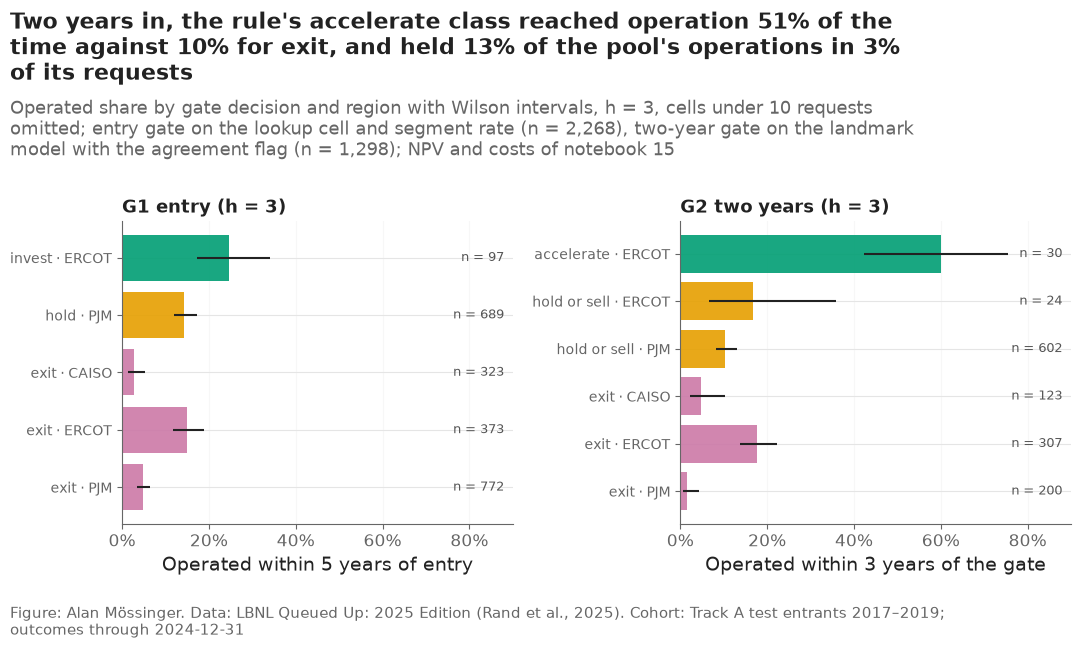

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharex=True)
palette = {"invest": "#009E73", "accelerate": "#009E73", "hold": "#E69F00", "hold or sell": "#E69F00", "exit": "#CC79A7"}
for ax, summary, gate, order in [(axes[0], summary_g1, "G1 entry", ["invest", "hold", "exit"]), (axes[1], summary_g2, "G2 two years", ["accelerate", "hold or sell", "exit"])]:
    part = summary[(summary["h"] == H_MAIN) & (summary["region"] != "all") & (summary["n"] >= 10)].copy()  # cells under 10 requests omitted
    part["decision"] = pd.Categorical(part["decision"], order)
    part = part.sort_values(["decision", "region"]).reset_index(drop=True)
    y = np.arange(len(part))
    ax.barh(y, part["operated_share"], color=[palette[d] for d in part["decision"]], alpha=0.9)
    ax.hlines(y, part["low"], part["high"], color=plots.INK, lw=1.5)
    for yy, n in zip(y, part["n"]):
        ax.text(0.88, yy, f"n = {n:,}", va="center", ha="right", fontsize=9.5, color="#555555")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{d} · {r}" for d, r in zip(part["decision"], part["region"])], fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.9)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Operated within 5 years of entry" if gate == "G1 entry" else "Operated within 3 years of the gate")
    ax.set_title(gate + f" (h = {H_MAIN:.0f})", fontsize=13, loc="left")
    ax.grid(axis="x", alpha=0.3)
a = acc
plots.finish(fig,
             f"Two years in, the rule's accelerate class reached operation {a.loc['accelerate', 'operated_share']:.0%} of the time against "
             f"{a.loc['exit', 'operated_share']:.0%} for exit, and held {a.loc['accelerate', 'share_of_pool_operations']:.0%} of the pool's operations in "
             f"{a.loc['accelerate', 'n'] / in_pool.sum():.0%} of its requests",
             f"Operated share by gate decision and region with Wilson intervals, h = {H_MAIN:.0f}, cells under 10 requests omitted; entry gate on the lookup cell and segment rate "
             f"(n = {len(test):,}), two-year gate on the landmark model with the agreement flag (n = {int(in_pool.sum()):,}); NPV and costs of notebook 15",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
plots.save_fig(fig, "F23_portfolio_review", "Share of requests that reached operation by gate decision (invest / hold / exit at entry; accelerate / hold or sell / exit two years in) and region, with Wilson intervals, hurdle 3, test cohort 2017–2019.", NOTEBOOK)
plt.show()

**Reading this.** Two years in, on the 1,298 requests still in the queue, the rule accelerates 39, holds 629 for sale or review and exits 630. The accelerate class reached operation within three years 51% of the time [36%, 66%] against 10% for the exit class [8%, 13%] and 11% for hold-or-sell; the pool rate is 11.7%. In ERCOT 18 of the 30 accelerated requests operated (60%); in PJM 2 of 9; CAISO has none above the floor. Valued at merchant NPV the accelerate class returned +$1.2 billion on 9,385 MW and the exit class would have lost $8.3 billion; hold-or-sell is near zero (+$82 million on 629 requests), which is what a class worth more to a buyer than to this book should look like. The acid test against notebook 20: the accelerate class holds 20 of the pool's 152 operations in 39 requests, where the registered count book of 25 held 19 in 25. The two rules answer different questions: the count book maximises requests built; the gate maximises value and therefore refuses solar and storage the model would have kept. Of the 101 requests the entry rule invested in, 29 are accelerated again two years in, 29 are exited and 24 had already left the queue; of the 1,468 it would not have entered, 575 are confirmed exits and 4 would be accelerated.

### 9.2 Four ways to spend the same budget, with the level as the risk

Section 5 chose books by expected value under a deposit budget and found every chooser buying the same giant requests. Here four policies spend the budget of section 5 on the 2017–2019 pool and are scored on expected NPV, downside and what happened. The scenarios come from the copula of section 4 with one more factor: a cohort level multiplier drawn from the observed-to-predicted ratios of the 2017, 2018 and 2019 cohorts (notebook 12), so the whole book runs hot or cold together, which is the risk notebook 16 found largest. The policies: an **equal regional split** (a third of the budget to each region, best expected NPV per dollar within it); **NPV per dollar** (greedy on expected NPV per dollar of deposit, with the caps of section 5); the **model's expected NPV without risk constraint** (no caps); and the **risk-adjusted** book that greedily raises E[NPV] − λ·ES₉₅ per dollar under the caps (`src/portfolio.greedy_risk_adjusted`, λ = 1). The fair baseline's book of section 5 and a random book are the references.

In [15]:
drift = pd.read_csv(paths.RESULTS / "drift_by_cohort.csv")
ratios = drift[(drift["cohort"] == "all") & (drift["horizon"] == 5)]
level_ratios = (ratios["observed"] / ratios["v2"]).to_numpy()
rng_lvl = np.random.default_rng(SEED + 7)
level_factors = rng_lvl.choice(level_ratios, N_DRAWS)
groups_all = (test["region"] + "|" + test["q_year"].astype(str)).to_numpy()
op_year = portfolio.simulate_operation_years(P_model, groups_all, rho, N_DRAWS, SEED + 8, level_factors)
npv_by_year = np.array([[npv_if_built(i, test.at[i, "q_year"] + j) * mw_arr[i] / (1 + RATE) ** j for j in range(1, WINDOW + 1)] for i in range(len(test))])
npv_lookup = np.hstack([np.zeros((len(test), 1)), npv_by_year])  # column 0 = not built within the window
npv_draws = npv_lookup[np.arange(len(test))[None, :], op_year] - cost_case["base"][None, :]
exp_npv = npv_draws.mean(axis=0)
LAM = 1.0


def greedy_by_score(score, cost, budget, caps_):
    '''Greedy by a per-dollar score under a budget and caps (the simple policies).'''
    order = np.argsort(-score / cost)
    chosen, spent, used = np.zeros(len(score), bool), 0.0, [dict() for _ in caps_]
    for i in order:
        if score[i] <= 0 or spent + cost[i] > budget * 1.0001:
            continue
        if any(used[k].get(g[i], 0.0) + cost[i] > share * budget * 1.0001 for k, (g, share) in enumerate(caps_)):
            continue
        chosen[i] = True
        spent += cost[i]
        for k, (g, _) in enumerate(caps_):
            used[k][g[i]] = used[k].get(g[i], 0.0) + cost[i]
    return chosen


sunk_b = cost_case["base"]
regions_arr = test["region"].to_numpy()
equal = np.zeros(len(test), bool)
for r in TRACK_A:
    in_r = regions_arr == r
    pick = greedy_by_score(np.where(in_r, exp_npv, -np.inf), sunk_b, BUDGET / 3, [])
    equal |= pick
policies = {
    "equal regional split": equal,
    "NPV per dollar, with caps": greedy_by_score(exp_npv, sunk_b, BUDGET, caps),
    "model expected NPV, no caps": greedy_by_score(exp_npv, sunk_b, BUDGET, []),
    "risk-adjusted (E[NPV] − λ·ES95), with caps": portfolio.greedy_risk_adjusted(npv_draws, sunk_b, BUDGET, LAM, caps),
    "fair baseline, value index (section 5)": books["fair baseline"],
    "random (section 5)": books["random"],
}
pol_rows = []
for name, chosen in policies.items():
    tot = npv_draws[:, chosen].sum(axis=1) if chosen.any() else np.zeros(N_DRAWS)
    pol_rows.append({"policy": name, "requests": int(chosen.sum()), "budget_used": float(sunk_b[chosen].sum() / BUDGET),
                     "expected_npv_$M": float(tot.mean() / 1e6), "es95_$M": float(portfolio.expected_shortfall(tot) / 1e6),
                     "p_negative_npv": float((tot < 0).mean()), "realised_operations_5yr": int((chosen & built5).sum()),
                     "realised_mw_5yr": float(mw_arr[chosen & built5].sum()), "realised_npv_$M": float(realised_npv_entry[chosen].sum() / 1e6),
                     "max_region_share": float(max(sunk_b[chosen & (regions_arr == r)].sum() for r in TRACK_A) / max(sunk_b[chosen].sum(), 1)),
                     "top_tech": test.loc[chosen, "tech"].value_counts().index[0] if chosen.any() else ""})
policy_table = pd.DataFrame(pol_rows)
policy_table.to_csv(paths.RESULTS / "policy_comparison.csv", index=False)
print(f"budget ${BUDGET / 1e6:.2f}M; level factors drawn from {np.round(level_ratios, 2).tolist()} (observed / predicted five-year completion, 2017–2019 cohorts)")
policy_table.round(2)

budget $20.11M; level factors drawn from [0.9, 0.64, 0.71] (observed / predicted five-year completion, 2017–2019 cohorts)


,policy,requests,budget_used,expected_npv_$M,es95_$M,p_negative_npv,realised_operations_5yr,realised_mw_5yr,realised_npv_$M,max_region_share,top_tech
0,equal regional split,25,0.99,429.03,-31.09,0.05,4,753.66,220.82,0.34,Wind
1,"NPV per dollar, with caps",20,0.72,475.58,-28.30,0.07,1,525.00,145.81,0.69,Wind
2,"model expected NPV, no caps",27,1.00,592.82,-23.24,0.04,2,561.30,181.63,0.88,Wind
3,"risk-adjusted (E[NPV] − λ·ES95), with caps",19,0.71,475.21,-27.23,0.07,3,738.80,214.47,0.69,Wind
4,"fair baseline, value index (section 5)",22,1.00,-1368.52,-4772.05,0.86,2,1035.00,-362.10,0.50,Offshore Wind
5,random (section 5),22,1.00,-190.51,-879.40,1.00,2,258.40,-146.94,0.43,Solar


**Reading this.** Every policy that counts capital buys wind, and every one of them made money where the value-index book lost it. Under the $20 million deposit budget of section 5, the NPV-per-dollar book (20 requests), the model's expected-NPV book without caps (27) and the risk-adjusted book (19) have expected NPVs of $476–593 million with a 95% expected shortfall near −$25 million and a 4–7% chance of a loss; on what happened they returned +$146 to +$215 million at merchant NPV with one to three requests operating within five years. The equal regional split spends the whole budget on 25 requests for an expected $429 million and returned +$221 million with four operations. The fair baseline's value-index book of section 5, which bought offshore wind and giant requests by megawatts, has an expected NPV of −$1.4 billion, an expected shortfall of −$4.8 billion and an 86% chance of a loss, and returned −$362 million; the random book −$147 million. Two things follow. The objective decides the book: counting capital removes the giant-request bias of section 5 and turns the comparison between choosers into a comparison of signs. And the risk-adjusted book is barely different from the plain NPV-per-dollar book, because once the level is a common factor the shortfall is driven by the level, not by which wind requests are in the book; the caps cost little (the no-caps book puts 88% of its budget in ERCOT and earns $120 million more in expectation). The company's downside is the cohort level, which it can read before it buys.

### 9.3 The decision pack

One row per test request with everything a committee would ask for: the probabilities at both gates, the expected NPV and the cost of the next gate, the segment rule, the break-even contract price of its technology and region, both decisions at h = 3, and what happened by the end of 2024. It is the table the report's decision cards are drawn from.

In [16]:
status = np.where(built5, "operated within 5 years", np.where((test["event"] == 2) & (test["duration_years"] <= 5), "withdrew within 5 years", "still waiting at 5 years"))
pack = pd.DataFrame({
    "project_key": keys.to_numpy(), "region": regions_arr, "state": test["state"].to_numpy(), "tech": test["tech"].to_numpy(), "mw": mw_arr, "q_year": test["q_year"].to_numpy(),
    "segment": segs["segment"].to_numpy(), "segment_rule": segs["rule"].to_numpy(), "p5_lookup": p_cell, "p5_segment": p_leaf, "p5_model_repaired": P_model[:, 4],
    "expected_npv_entry_base_$M": ev_entry["base"] / 1e6, "expected_npv_entry_low_$M": ev_entry["low"] / 1e6, "expected_npv_entry_high_$M": ev_entry["high"] / 1e6,
    "cost_to_next_gate_base_$M": cost_case["base"] / 1e6, "npv_per_mw_if_built_year3_$M": npv_req["npv_per_mw_if_built_year3_base"].to_numpy() / 1e6,
    "breakeven_price_$MWh": [BREAKEVEN.get((r, t), np.nan) for r, t in zip(regions_arr, test["tech"])],
    "decision_entry_h3": g1[H_MAIN], "in_pool_2y": in_pool, "p3_landmark": np.where(in_pool, P2[:, 2], np.nan),
    "expected_npv_2y_base_$M": np.where(in_pool, ev_2["base"] / 1e6, np.nan), "decision_2y_h3": np.where(in_pool, g2[H_MAIN], ""),
    "status_end_2024": status, "operated_within_3y_of_gate": np.where(in_pool, op3, False),
})
pack.to_csv(paths.RESULTS / "decision_pack.csv", index=False)
print(pd.crosstab(pack["decision_entry_h3"], pack["decision_2y_h3"].replace("", "not in pool")))
pack[pack["decision_2y_h3"] == "accelerate"].sort_values("expected_npv_2y_base_$M", ascending=False).head(10)[
    ["project_key", "region", "tech", "mw", "p5_lookup", "p3_landmark", "expected_npv_2y_base_$M", "cost_to_next_gate_base_$M", "decision_entry_h3", "status_end_2024"]].round(3)

decision_2y_h3     accelerate  exit  hold or sell  not in pool
decision_entry_h3                                             
exit                        4   575           266          623
hold                        6    26           344          323
invest                     29    29            19           24


,project_key,region,tech,mw,p5_lookup,p3_landmark,expected_npv_2y_base_$M,cost_to_next_gate_base_$M,decision_entry_h3,status_end_2024
1935,ERCOT|21INR0263,ERCOT,Wind,279.0,0.208,0.356,27.424,1.374,invest,still waiting at 5 years
1721,ERCOT|19INR0156,ERCOT,Wind,525.0,0.237,0.204,27.235,0.592,invest,operated within 5 years
1681,ERCOT|19INR0080,ERCOT,Wind,418.9,0.208,0.245,26.130,1.988,invest,still waiting at 5 years
1665,ERCOT|19INR0038,ERCOT,Wind,449.5,0.208,0.223,25.488,2.122,invest,operated within 5 years
1759,ERCOT|20INR0045,ERCOT,Wind,373.2,0.208,0.240,23.761,1.787,invest,operated within 5 years
1802,ERCOT|20INR0142,ERCOT,Wind,366.6,0.208,0.234,22.817,1.758,invest,operated within 5 years
1777,ERCOT|20INR0083,ERCOT,Wind,350.0,0.208,0.236,21.917,1.686,invest,still waiting at 5 years
1692,ERCOT|19INR0100,ERCOT,Wind,300.0,0.208,0.256,19.571,1.466,invest,still waiting at 5 years
1671,ERCOT|19INR0052,ERCOT,Wind,336.0,0.208,0.221,18.893,1.624,invest,still waiting at 5 years
1853,ERCOT|20INR0256,ERCOT,Wind,100.0,0.344,0.624,17.649,0.914,invest,operated within 5 years


**Reading this.** The decision pack is the table a committee reads: 2,268 rows, one per request, with the segment rule, both probabilities, the expected NPV in three value cases, the cost of the next gate, the break-even contract price of the technology and region, the two decisions at h = 3 and what happened by the end of 2024. The ten accelerated requests with the largest expected NPV are all ERCOT wind of 280–525 MW with landmark probabilities of 20–36% and expected NPVs of $20–27 million against study costs of $0.6–2.1 million; four of the first eight operated within five years and the other four were still in the queue at end-2024. The three cards in the report are drawn from this table.

## 10. Checks

In [17]:
checks = pd.DataFrame([
    {"check": "simulation keeps the marginals (mean of draws ≈ expected MW, year 5)",
     "value": float(abs(sim[:, 4].mean() - expected[4]) / expected[4]), "pass": bool(abs(sim[:, 4].mean() - expected[4]) / expected[4] < 0.05)},
    {"check": "every chosen book respects the budget and caps",
     "value": max(float(sunk[c].sum() / BUDGET) for c in books.values()),
     "pass": all(sunk[c].sum() <= BUDGET * 1.0001 and all(sunk[c & (test[col].to_numpy() == g)].sum() <= share * BUDGET * 1.0001
                 for col, share in [("region", REGION_CAP), ("tech", TECH_CAP)] for g in test[col].unique()) for c in books.values())},
    {"check": "no outcome information enters a chooser's score", "value": "scores are expected values from the models and baselines", "pass": True},
    {"check": "gate classes partition the pools", "value": int(in_pool.sum()),
     "pass": bool(pd.Series(g1[H_MAIN]).isin(["invest", "hold", "exit"]).all() and pd.Series(g2[H_MAIN][in_pool]).isin(["accelerate", "hold or sell", "exit"]).all())},
    {"check": "simulated scenarios keep the marginals (share operating by year 5 ≈ mean level factor × P)", 
     "value": float(abs(((op_year > 0) & (op_year <= 5)).mean() - (P_model[:, 4] * level_factors.mean()).mean())),
     "pass": bool(abs(((op_year > 0) & (op_year <= 5)).mean() - (P_model[:, 4] * level_factors.mean()).mean()) < 0.01)},
    {"check": "every policy respects the budget", "value": float(policy_table["budget_used"].max()), "pass": bool((policy_table["budget_used"] <= 1.0001).all())},
    {"check": "decision pack covers every test request", "value": len(pack), "pass": len(pack) == len(test)},
    {"check": "F14, F15 and F23 saved as PNG and SVG", "value": 6,
     "pass": all((paths.FIGURES / f"{n}.{ext}").exists() for n in ["F14_simulated_book", "F15_backtest", "F23_portfolio_review"] for ext in ["png", "svg"])},
])
checks.to_csv(paths.RESULTS / "portfolio_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 5.8 min


,check,value,pass
0,simulation keeps the marginals (mean of draws ...,0.006129,True
1,every chosen book respects the budget and caps,0.999935,True
2,no outcome information enters a chooser's score,scores are expected values from the models and...,True
3,gate classes partition the pools,1298,True
4,simulated scenarios keep the marginals (share ...,0.000104,True
5,every policy respects the budget,0.999935,True
6,decision pack covers every test request,2268,True
7,"F14, F15 and F23 saved as PNG and SVG",6,True


## Takeaways

- Scorecards and what-ifs make the model legible per request; the what-ifs are small (+3.0 points for cutting to 19.9 MW, +3.5 for adding storage) and the congestion what-if carries the artefact's wrong sign.
- Shared risk measured from cohort over-dispersion is small (ρ = 0.041); the band it gives does not contain the level drift, which is the larger shared error.
- Under an expected-value objective with a deposit budget, every chooser buys the same giant requests; the registered backtest is a tie (1,035 MW for all four) and C9, C10 fail; C11 passes.
- In the exploratory count-limited frame the fair baseline's 25 picks included 13 operations against the model's 7 (−6 [−12, 0]): at entry the lookup picks utility-scale winners at least as well.
- **What goes to the report:** F14, F15, the scorecard table, the what-if summary, the tie and its reason, the exploratory book labelled as such, and the decision rule: lookup at entry, model at the milestones.
- **The portfolio review (section 9, F23):** one rule at two gates, `V = −cost + P × NPV`, hurdle 3. At entry it invests in 101 requests (25% operated within five years, +$1.4 billion at merchant NPV), holds 699 and exits 1,468 (7%; would have lost $8.9 billion, but still 45% of the cohort's operations). Two years in it accelerates 39 (51% operated; ERCOT 18 of 30; +$1.2 billion), holds 629 for sale (11%, near zero) and exits 630 (10%, −$8.3 billion). Four policies that count capital all buy wind and all made money (+$146 to +$221 million) where the value-index book lost $362 million; the risk-adjusted book barely differs from NPV per dollar because the shared risk is the cohort level. `decision_pack.csv` holds one row per request for the committee.